# 03 · Error analysis

**Why:** mAP tells us *how much* the model gets wrong, not *what* or *why*. Here we look at every mistake `models/best.pt` makes on the val set, trace each kind of mistake back to our data, our labelling rules or the settings, and turn that into hypotheses that the data lead and the modelling lead can test in the next round.

1. **Scores and confusion matrix** on the 25 val frames.
2. **Every box matched to a label,** so each mistake gets a type.
3. **The ball:** which balls are missed, and what they have in common.
4. **Gallery** of the mistakes.
5. **Worst frames:** where in the clip the mistakes are.
6. **Confidence per class:** what another threshold would change.
7. **Failure hypotheses** for the next round.

**Run:** open in VS Code or Jupyter with the project's Python and *Run All*. Needs `models/best.pt` (in git) and `data/cycle-ball-dataset/` (built by `python data/prepare_dataset.py` or notebook 01). Figures are saved to `reports/error_analysis/` (not in git, because they show video frames).

**Author:** Ryan Omondi (error analysis, role C)

> **GenAI:** I used AI to write the code and a first draft of the text from our task list (sections 1–7 above), then had it go back over the whole notebook against the brief. Checked against my teammates' work:
> - **Same numbers as Artem:** the scores in §1 match row E1-26v1b of his mAP log, so we analyse the same model and val set he reports.
> - **Linked to Ivayla's labelling rules:** the ball and bike failures in §7 point back to how we labelled (half-hidden and blurred balls are boxed, so missing one is a real miss).
>
> Caught and fixed on the way:
> - the confusion matrix first used Ultralytics' default confidence of 0.001, which filled the background column with weak boxes; it now uses 0.25, the confidence we actually work with (§1b);
> - the first draft said 21 of the 48 training balls are in a crowd; the real count is 9 of 48, which makes hypothesis 1 stronger;
> - a crowding score (overlapping boxes per frame) barely followed the misses, so we dropped it and kept the scrum as a hypothesis picked by looking at the frames;
> - the first draft called frame 53 a ball in the air; in video frames 51–55 the label box sits on a rider's head and no ball is visible, so it is now a possible label mistake, like frame 74 that Artem flagged;
> - the first draft said the model no longer boxes the referee; that holds for the val frames only, the full video still has it in two short runs (hypothesis 7).

## Settings
All paths and numbers used below are set here, so nothing is hidden in the code.

In [1]:
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import Image, display
from ultralytics import YOLO
from ultralytics.utils.metrics import box_iou

ROOT = Path.cwd().parent                        # this notebook lives in notebooks/
DATA = ROOT / "data/cycle-ball-dataset"         # built by data/prepare_dataset.py (dataset v1b: 48 train / 25 val)
MODEL = ROOT / "models/best.pt"                 # E1-26v1b from notebook 02: YOLO26s fine-tuned on our frames
IMGSZ = 640                                     # the size the model was trained at; always predict at the same size
CONF = 0.25                                     # a box counts from this confidence, as in models/detections.csv
IOU_HIT = 0.5                                   # overlap with a label of the same class that makes a hit (the "50" in mAP50)
IOU_NEAR = 0.1                                  # between this and IOU_HIT: the right object, but a badly placed box
RUNS = ROOT / "runs/error_analysis"             # Ultralytics output (not in git)
REPORTS_DIR = ROOT / "reports/error_analysis"   # figures for the report (not in git: they show video frames)
W, H = 3024, 1078                               # every frame of our video
XY = ["x1", "y1", "x2", "y2"]                   # box corners in pixels
DEVICE = "mps" if torch.backends.mps.is_available() else 0 if torch.cuda.is_available() else "cpu"

REPORTS_DIR.mkdir(parents=True, exist_ok=True)
model = YOLO(MODEL)
names = model.names                             # {0: 'player', 1: 'ball', 2: 'bike', 3: 'goal'}
iou = lambda a, b: box_iou(torch.tensor(np.asarray(a, float)), torch.tensor(np.asarray(b, float))).numpy()

## 1. Scores on the val set

The starting point. These must be the numbers of row **E1-26v1b** in the mAP log ([`modeling/README.md` §9](../modeling/README.md)); otherwise we would be analysing another model or another val set than the one the modelling side reports.

In [2]:
scores = model.val(data=DATA / "data.yaml", imgsz=IMGSZ, device=DEVICE, project=RUNS, name="val", exist_ok=True, verbose=False)
print(f"all classes: mAP50 {scores.box.map50:.3f}, mAP50-95 {scores.box.map:.3f}")
pd.DataFrame({"precision": scores.box.p, "recall": scores.box.r, "AP50": scores.box.ap50, "AP50-95": scores.box.ap},
             index=[names[c] for c in scores.box.ap_class_index]).round(3)

Ultralytics 8.4.193 🚀 Python-3.12.13 torch-2.15.0 MPS (Apple M2)


YOLO26s summary (fused): 120 layers, 9,466,728 parameters, 0 gradients, 20.8 GFLOPs


val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 858.4±35.0 MB/s, size: 457.9 KB)


val: Scanning /Users/arinaloychenko/Thomas More/computer-vision/data/cycle-ball-dataset/labels/val.cache... 25 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 25/25 13.1Mit/s 0.0s

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 50% ━━━━━━────── 1/2 2.0s/it 0.6s<2.0s

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 1.9it/s 1.1s

                   all         25        261      0.919       0.79       0.84       0.59


Speed: 0.1ms preprocess, 22.7ms inference, 0.0ms loss, 1.3ms postprocess per image


Results saved to /Users/arinaloychenko/Thomas More/computer-vision/runs/error_analysis/val


all classes: mAP50 0.840, mAP50-95 0.590


,precision,recall,AP50,AP50-95
player,0.946,0.895,0.934,0.552
ball,0.834,0.480,0.521,0.226
bike,0.905,0.787,0.910,0.587
goal,0.992,1.000,0.995,0.995


**Findings:** the same numbers as E1-26v1b in the mAP log (mAP50 0.840, mAP50-95 0.590), so we analyse the right model. `goal` is solved (0.995). `player` and `bike` are good at AP50 (0.93 and 0.91) but drop to 0.55–0.59 at AP50-95: found, but their boxes are often not tight. The **ball is clearly the weakest class**: AP50 0.521, AP50-95 0.226.

### 1b. Confusion matrix

Each **column** is the true class, each **row** what the model predicted. The **background** row holds labels the model missed (false negatives), the **background** column boxes it drew where no label is (false positives).

Ultralytics builds this matrix from every box the validation run keeps, down to confidence 0.001, which floods the background column with weak boxes nobody would use. So we validate a second time at our threshold, 0.25, only for the matrix. Ultralytics also matches boxes its own way (for example at IoU 0.45, where section 2 uses 0.5), so the counts differ a little from section 2.

Ultralytics 8.4.193 🚀 Python-3.12.13 torch-2.15.0 MPS (Apple M2)


YOLO26s summary (fused): 120 layers, 9,466,728 parameters, 0 gradients, 20.8 GFLOPs


val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 5613.5±1023.5 MB/s, size: 454.4 KB)


val: Scanning /Users/arinaloychenko/Thomas More/computer-vision/data/cycle-ball-dataset/labels/val.cache... 25 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 25/25 4.2Mit/s 0.0s

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 50% ━━━━━━────── 1/2 1.2s/it 0.4s<1.2s

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 2.9it/s 0.7s

                   all         25        261      0.921       0.79      0.816      0.579


Speed: 0.1ms preprocess, 10.6ms inference, 0.0ms loss, 1.0ms postprocess per image


Results saved to /Users/arinaloychenko/Thomas More/computer-vision/runs/error_analysis/val_conf


,true player,true ball,true bike,true goal,true background
pred player,91,0,1,0,9
pred ball,0,15,0,0,6
pred bike,0,0,84,0,23
pred goal,0,0,0,50,0
pred background,6,10,4,0,0


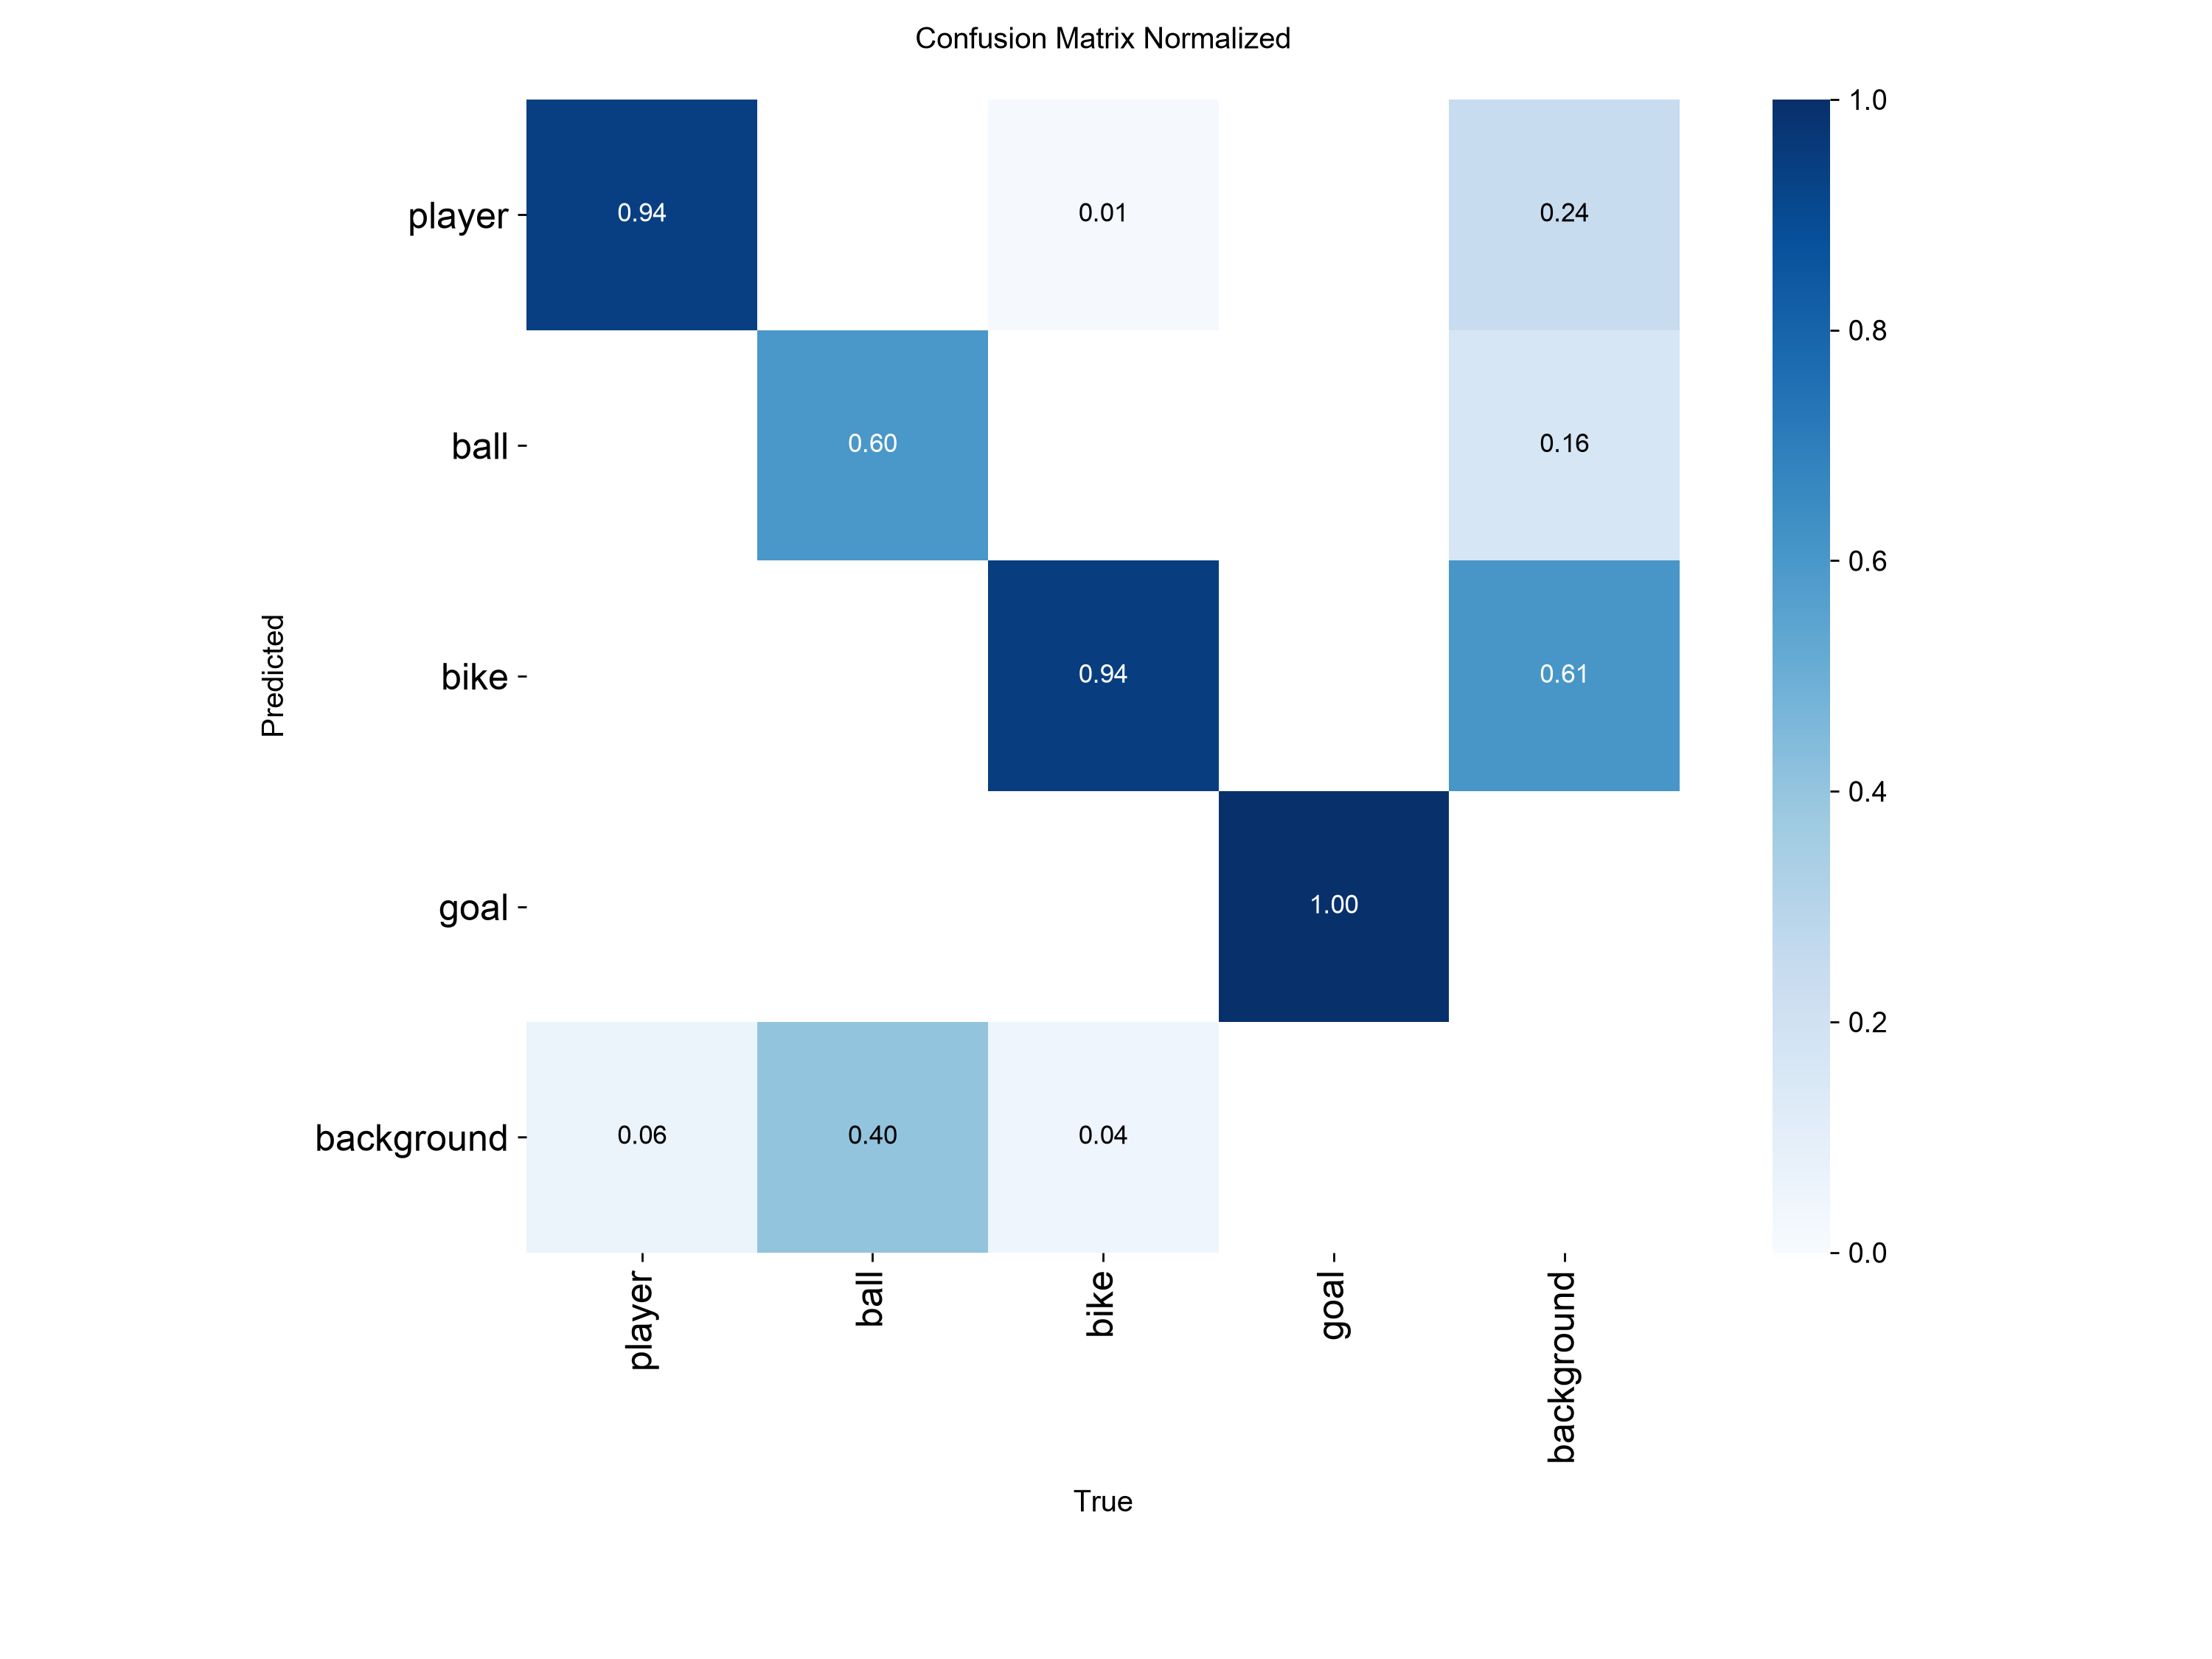

In [3]:
at_conf = model.val(data=DATA / "data.yaml", imgsz=IMGSZ, device=DEVICE, conf=CONF, project=RUNS, name="val_conf", exist_ok=True, verbose=False)
classes = list(names.values()) + ["background"]
display(pd.DataFrame(at_conf.confusion_matrix.matrix.astype(int), index=[f"pred {c}" for c in classes], columns=[f"true {c}" for c in classes]))
Image(filename=RUNS / "val_conf" / "confusion_matrix_normalized.png", width=600)

**Findings:**
- **Almost no mix-ups between classes:** one box in the whole val set has the wrong class (a bike predicted as a player). The model knows what a rider, a bike and a ball look like; its mistakes are about *finding* objects and *placing* boxes.
- **Ball:** 10 of the 25 true balls are in the background row: not found.
- **Bike and player:** many more extra boxes than missed ones (bike 23 extra against 4 missed, player 9 against 6).

## 2. Every box matched to a label

The matrix gives counts, not reasons. So we predict on the 25 val frames ourselves and match each box to a label:

- **Matching:** boxes from confidence 0.25, highest confidence first; each takes the free label of its own class it overlaps most. IoU ≥ 0.5 is a hit (TP). This follows the same idea as Ultralytics, but we use it to sort mistakes, not to report scores.
- **False positive (FP) types:** *duplicate* (a second box on an object that already has one), *poor box* (the right object, IoU 0.1–0.5), *nothing there*.
- **False negative (FN) types:** *low confidence* (a good box exists, but under 0.25), *poor box*, *not seen* (no box of that class on it at any confidence down to 0.01).

We predict at confidence 0.01 so that the *low confidence* misses are visible too; boxes from 0.25 up are the same as in a normal run.

In [4]:
def read_labels(split):
    """Every label box of one split, in pixels."""
    rows = []
    for path in sorted((DATA / "labels" / split).glob("*.txt")):
        for line in path.read_text().splitlines():
            c, x, y, w, h = map(float, line.split())
            rows.append([int(path.stem[6:]), names[int(c)], (x - w / 2) * W, (y - h / 2) * H, (x + w / 2) * W, (y + h / 2) * H])
    return pd.DataFrame(rows, columns=["frame", "cls", *XY])


def match(conf=CONF):
    """Every label as TP or FN, and every extra box as FP, each with the type of mistake."""
    rows = []
    for frame, gt in labels.groupby("frame"):
        pr = preds[preds.frame == frame].sort_values("conf", ascending=False)
        overlap = iou(pr[XY], gt[XY])
        overlap[pr.cls.to_numpy()[:, None] != gt.cls.to_numpy()] = 0  # a box can only match a label of its own class
        kept = (pr.conf >= conf).to_numpy()
        taken = np.zeros(len(gt), bool)
        for i in np.flatnonzero(kept):                              # highest confidence first takes the best free label
            free = np.where(taken, 0, overlap[i])
            if free.max() >= IOU_HIT:
                taken[free.argmax()] = True
            else:
                best = overlap[i].max()
                kind = "duplicate" if best >= IOU_HIT else "poor box" if best >= IOU_NEAR else "nothing there"
                rows.append([frame, pr.cls.iat[i], "FP", kind, *pr[XY].iloc[i]])
        for j, column in enumerate(overlap.T):
            kind = ("" if taken[j] else "low confidence" if (column[~kept] >= IOU_HIT).any()
                    else "poor box" if (column[kept] >= IOU_NEAR).any() else "not seen")
            rows.append([frame, gt.cls.iat[j], "TP" if taken[j] else "FN", kind, *gt[XY].iloc[j]])
    return pd.DataFrame(rows, columns=["frame", "cls", "result", "kind", *XY])


labels = read_labels("val")
rows = []
for path in sorted((DATA / "images/val").glob("*.jpg")):
    boxes = model.predict(path, imgsz=IMGSZ, conf=0.01, device=DEVICE, verbose=False)[0].boxes
    rows += [[int(path.stem[6:]), names[int(c)], p, *xyxy] for c, p, xyxy in zip(boxes.cls.tolist(), boxes.conf.tolist(), boxes.xyxy.tolist())]
preds = pd.DataFrame(rows, columns=["frame", "cls", "conf", *XY])

results = match()
display(results.groupby(["cls", "result"]).size().unstack(fill_value=0))
results[results.result != "TP"].groupby(["cls", "result", "kind"]).size().unstack(fill_value=0)

result,FN,FP,TP
cls,,,
ball,11,4,14
bike,8,28,81
goal,0,0,50
player,7,12,90


kind           duplicate  low confidence  not seen  poor box
cls    result                                               
ball   FN              0               0        10         1
       FP              2               0         0         2
bike   FN              0               5         0         3
       FP              5               0         0        23
player FN              0               3         0         4
       FP              6               0         0         6

**Findings:**
- **Ball:** 14 of 25 found. Of the 11 misses, **10 are *not seen*: no ball box lands on them at any confidence.** So a lower threshold would not bring them back; the model does not recognise these balls. The 11th has a box just under the IoU 0.5 hit line. The 4 extra ball boxes all sit on a real ball (2 duplicates, 2 loose boxes): **the model never draws a ball in an empty spot.**
- **Player:** 90 of 97 found. None of the 12 extra boxes is on *nothing* (6 duplicates, 6 poor boxes): **in the 25 val frames, the fine-tuned model boxes no spectators, officials or referee,** which was the pretrained model's worst player problem (precision 0.23 in E0, notebook 02). It is not gone completely: in the full video the referee still ends up in a player box in two short runs of frames (hypothesis 7).
- **Bike:** 81 of 89 found, but 28 extra boxes, nearly all poor boxes: the model sees the bike but boxes part of it. Of the 8 misses, 5 have a well-placed box, but with confidence below 0.25.
- **Goal:** perfect.

**Conclusions:** two separate problems: (1) **ball recall**, some balls are invisible to the model; (2) **box placement** for bikes and players, which are found but split, doubled or cut off.

## 3. The ball

`touching` counts how many player and bike *labels* the ball's label overlaps: a rough measure of how much the ball is in among wheels, feet and riders. `height` is the y of the ball's centre in the frame (the floor is at roughly 880–930 px).

In [5]:
def touching(frame_labels, box):
    """How many player and bike labels overlap this box."""
    riders = frame_labels[frame_labels.cls.isin(["player", "bike"])]
    return int((iou([box], riders[XY]) > 0).sum())


balls = results[(results.cls == "ball") & (results.result != "FP")].copy()
balls["touching"] = [touching(labels[labels.frame == b.frame], b[XY]) for _, b in balls.iterrows()]
balls["width"] = balls.x2 - balls.x1
balls["height"] = (balls.y1 + balls.y2) / 2
balls.set_index("frame")[["result", "kind", "width", "touching", "height"]].round()

,result,kind,width,touching,height
frame,,,,,
13,FN,not seen,39.0,2,907.0
22,FN,not seen,50.0,2,896.0
32,TP,,36.0,1,887.0
34,TP,,30.0,1,886.0
39,FN,not seen,32.0,2,883.0
47,FN,poor box,38.0,3,883.0
53,FN,not seen,48.0,3,612.0
60,FN,not seen,50.0,4,892.0
65,FN,not seen,42.0,2,895.0


Hit rate by how crowded the ball is, the median size of found and missed balls, and the same crowding measure on the training balls.

In [6]:
balls["crowding"] = pd.cut(balls.touching, [-1, 1, 2, 9], labels=["0-1 boxes", "2 boxes", "3+ boxes"])
display(balls.groupby("crowding", observed=True).result.agg(balls="size", found=lambda r: (r == "TP").sum()))
display(balls.groupby("result")[["width", "touching"]].median())

train = read_labels("train")
train_touching = [touching(train[train.frame == b.frame], b[XY]) for _, b in train[train.cls == "ball"].iterrows()]
print(f"balls touching 2+ rider or bike labels: val {(balls.touching >= 2).sum()} of {len(balls)}, "
      f"train {sum(t >= 2 for t in train_touching)} of {len(train_touching)}")

,balls,found
crowding,,
0-1 boxes,8,8
2 boxes,13,6
3+ boxes,4,0


,width,touching
result,,
FN,41.67072,2.0
TP,35.71344,1.0


balls touching 2+ rider or bike labels: val 17 of 25, train 9 of 48


**Findings:**
- **The more the ball is in among riders and bikes, the less it is found:** every ball touching at most one rider or bike box is found, about half of those touching two, none touching three or more.
- **Size is not the reason:** missed balls are not smaller than found ones (median 42 against 36 px wide in the full frame). Artem saw the same in his first check (`modeling/README.md` §9).
- **Val is much more crowded than train:** 17 of the 25 val balls touch two or more rider or bike boxes, against only 9 of the 48 train balls. Our val range (frames 1–234) happens to hold a long scrum, so val mAP mostly measures the hardest situation, and the model saw few examples of it in training.
- **Link to our labelling rules:** the rules say to box the ball when at least half of it is visible, and a blurred ball too. So the half-hidden, blurred balls in a scrum *are* in the labels, and every one the model misses counts against it. That is the right choice for a tactical map (the ball matters most in a scrum), but it makes this the hardest part of the data.
- **Frame 53 is the only label off the floor:** its centre is at about 610 px, every other ball at 880–930 px. Zoomed in, and in video frames 51–55 around it, the box sits on a rider's head and no ball is visible, so this is probably a label mistake, not a ball in the air (section 4).

**Conclusions:** missed balls are a **clutter and occlusion problem**: a ball of a few pixels at `imgsz=640`, partly behind spokes, wheels and feet. Two things to try: more training examples of exactly that, and a bigger image size so the ball keeps more pixels (section 7).

## 4. Gallery of mistakes

Green: our labels. Red: the model's boxes from confidence 0.25. Each crop is centred on one mistake; the title gives the frame, the class and the type.

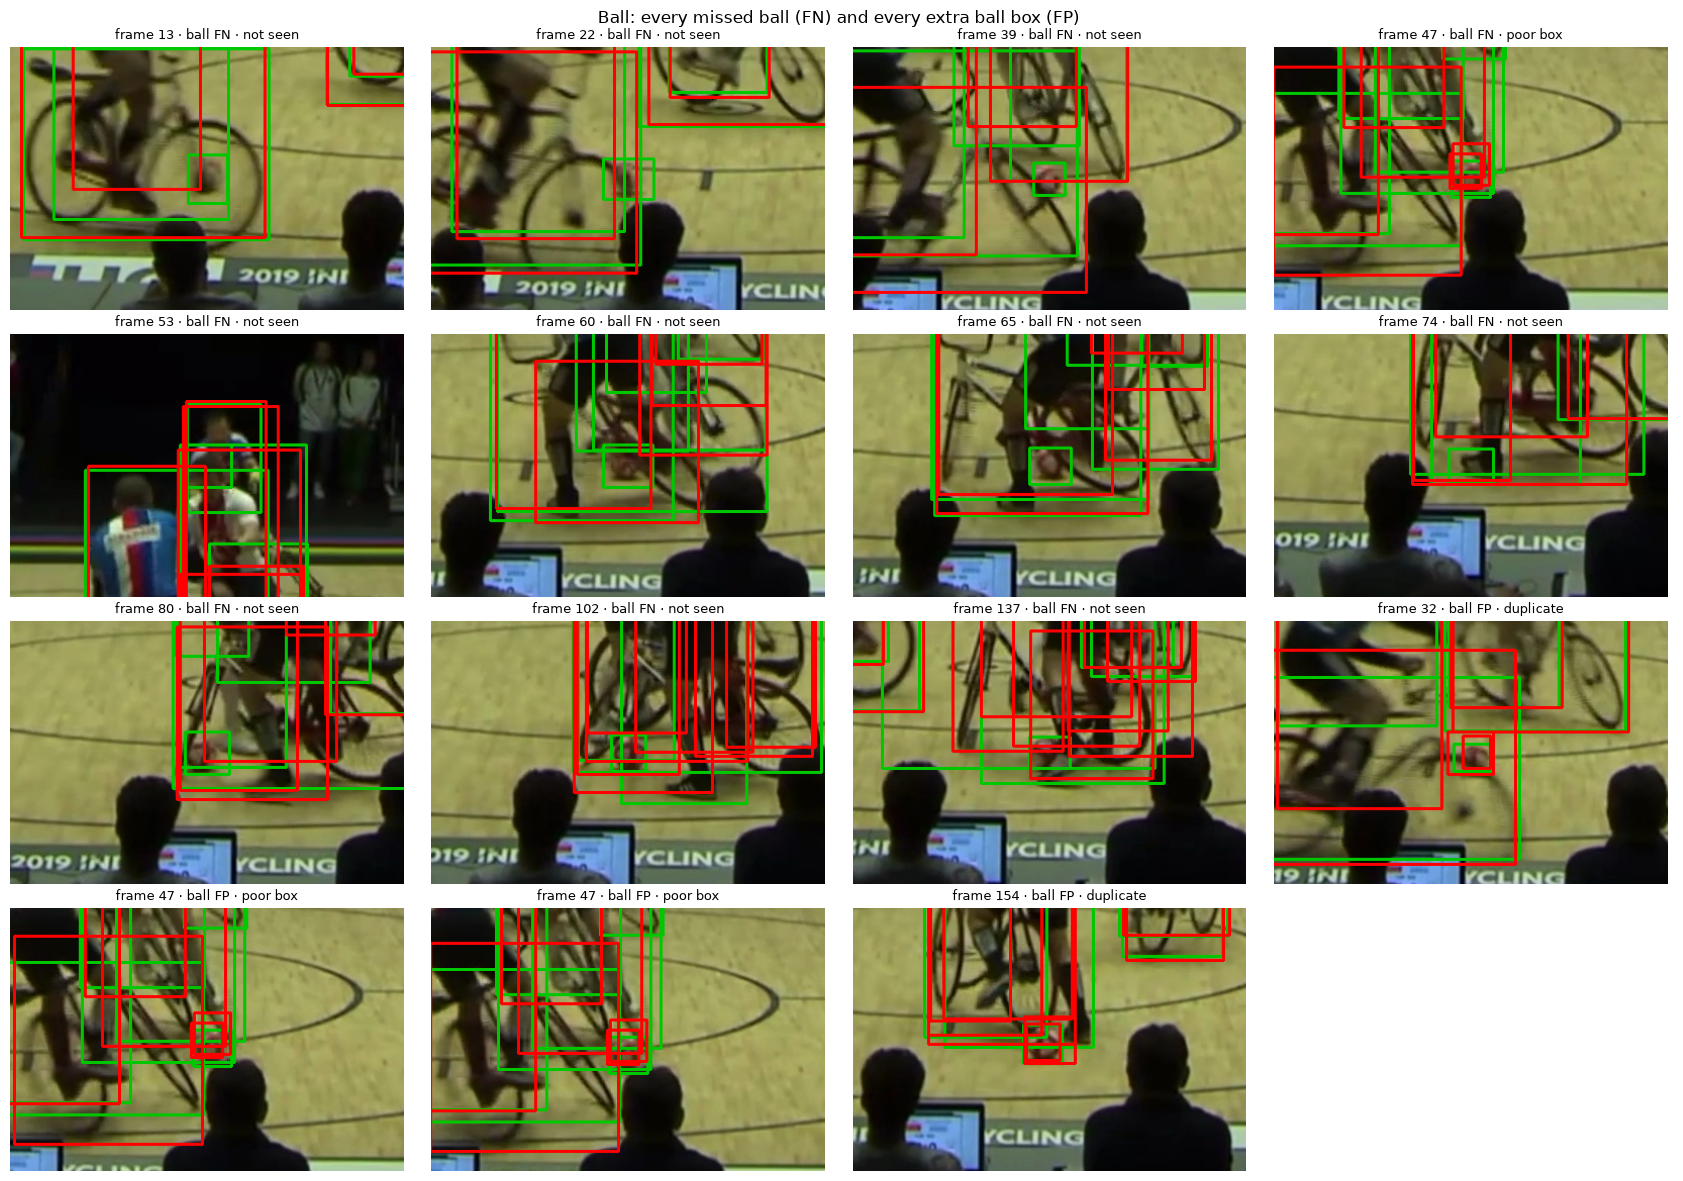

In [7]:
def gallery(rows, half, title, file_name):
    """One crop per mistake, 4 per row, with labels (green) and predictions from CONF (red)."""
    fig, axes = plt.subplots((len(rows) + 3) // 4, 4, figsize=(17, 3 * ((len(rows) + 3) // 4)))
    for ax in axes.flat:
        ax.axis("off")
    for ax, (_, r) in zip(axes.flat, rows.iterrows()):
        image = cv2.imread(str(DATA / "images/val" / f"frame_{r.frame:05d}.jpg"))
        for boxes, colour in ((labels[labels.frame == r.frame], (0, 200, 0)), (preds[(preds.frame == r.frame) & (preds.conf >= CONF)], (0, 0, 255))):
            for x1, y1, x2, y2 in boxes[XY].values.astype(int):
                cv2.rectangle(image, (x1, y1), (x2, y2), colour, 2)
        cx, cy = int(r.x1 + r.x2) // 2, int(r.y1 + r.y2) // 2
        ax.imshow(cv2.cvtColor(image[max(0, cy - half):cy + half, max(0, cx - 3 * half // 2):cx + 3 * half // 2], cv2.COLOR_BGR2RGB))
        ax.set_title(f"frame {r.frame} · {r.cls} {r.result} · {r.kind}", fontsize=9)
    fig.suptitle(title)
    fig.tight_layout()
    fig.savefig(REPORTS_DIR / file_name, dpi=120)
    plt.show()


gallery(results[(results.cls == "ball") & (results.result != "TP")].sort_values(["result", "frame"]), 130,
        "Ball: every missed ball (FN) and every extra ball box (FP)", "ball_mistakes.png")

**Findings:**
- **Missed balls:** in most crops the ball touches a wheel, a foot or a pedal, or is half hidden behind a rider, and it is blurred (frames 13, 22, 39, 60, 65). In frames 80, 102 and 137 the ball is clearly visible next to a foot or a wheel and is still missed. In frame 47 the model does box the ball, slightly off.
- **Frames 53 and 74: no ball inside the label box.** In 53 the box is on a rider's head (also in video frames 51–55), in 74 on a shoe. Artem noted the same two frames. If the data lead confirms them, these are label mistakes, not model mistakes, and the model misses 9 balls, not 11.
- **Extra ball boxes:** all on or right next to the real ball: a second, looser box (frames 32, 154) or two boxes that both miss IoU 0.5, one by a hair (frame 47).

Player and bike: up to three examples of each type of mistake.

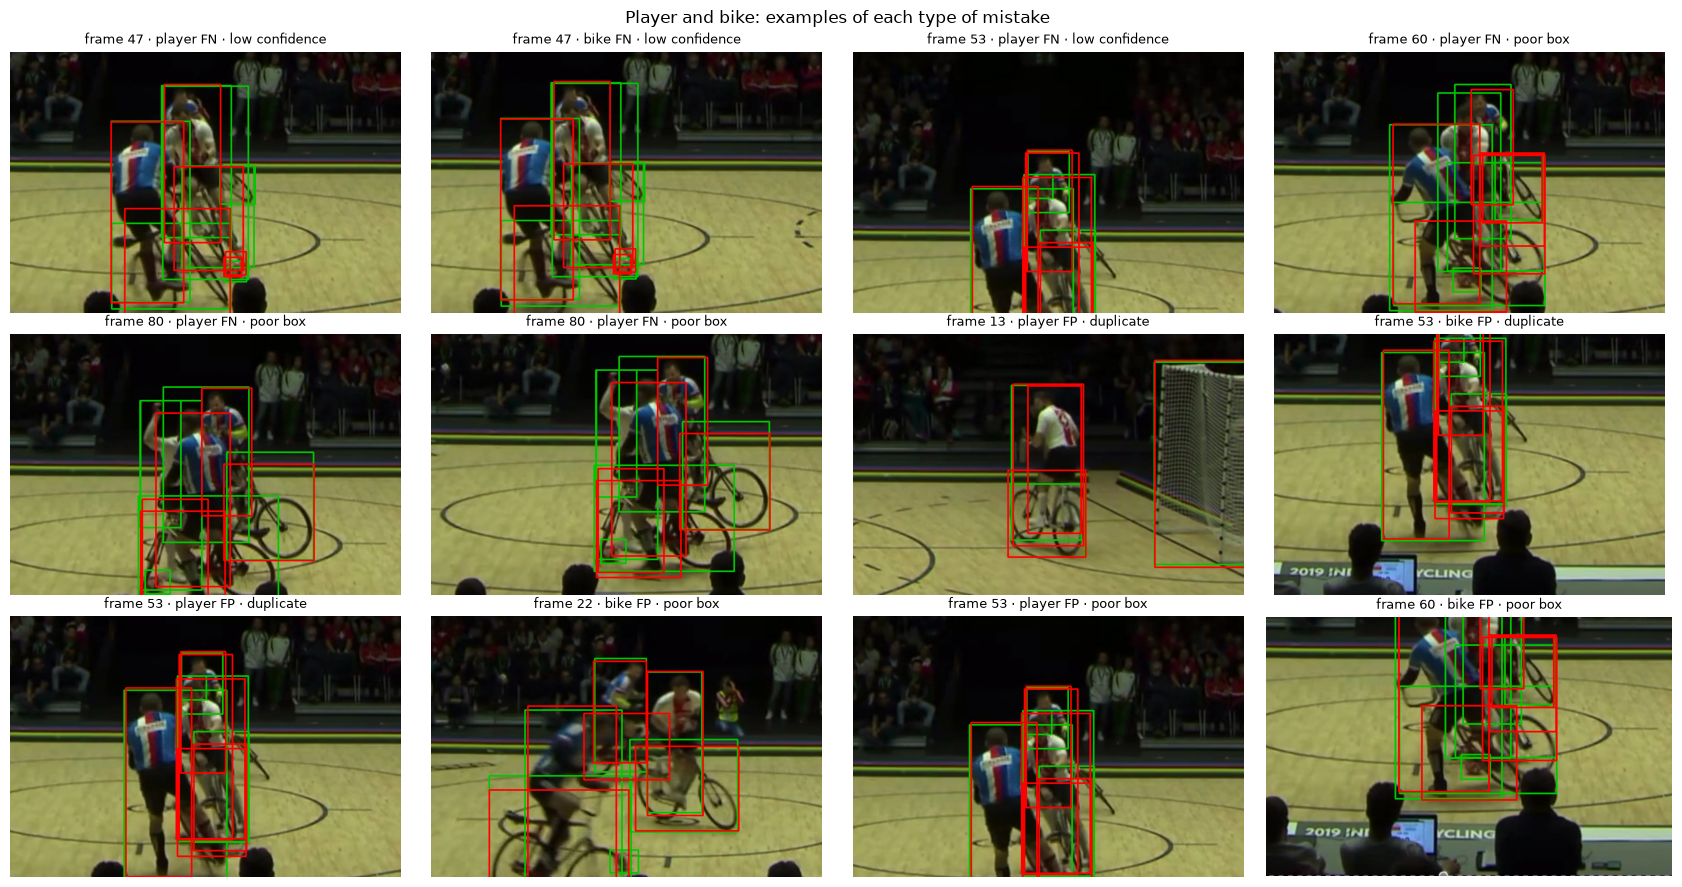

In [8]:
rider_mistakes = results[results.cls.isin(["player", "bike"]) & (results.result != "TP")]
gallery(rider_mistakes.sort_values(["result", "kind", "frame"]).groupby(["result", "kind"]).head(3), 230,
        "Player and bike: examples of each type of mistake", "rider_mistakes.png")

**Findings:** most player and bike mistakes happen with **three or four riders bunched together** around the ball (frames 47–80 in the gallery). Bikes overlap, riders stand in front of other riders' bikes, and the model splits one bike into two boxes, boxes only the front half, or puts a second box on a rider who already has one. A few happen with the riders apart (frames 13 and 22), for example two boxes on a lone rider near the goal in frame 13.

## 5. Worst frames

The lecturer's habit for any model: look at the *top losses*, the examples it gets most wrong. Here: the number of mistakes per val frame. `SCRUM` marks the stretch where, in the gallery, three or four riders are bunched around the ball (picked by eye).

frames 47-143 (11 of 25 val frames) hold {'player + bike mistakes': 43, 'balls missed': 8} of {'player + bike mistakes': 55, 'balls missed': 11}


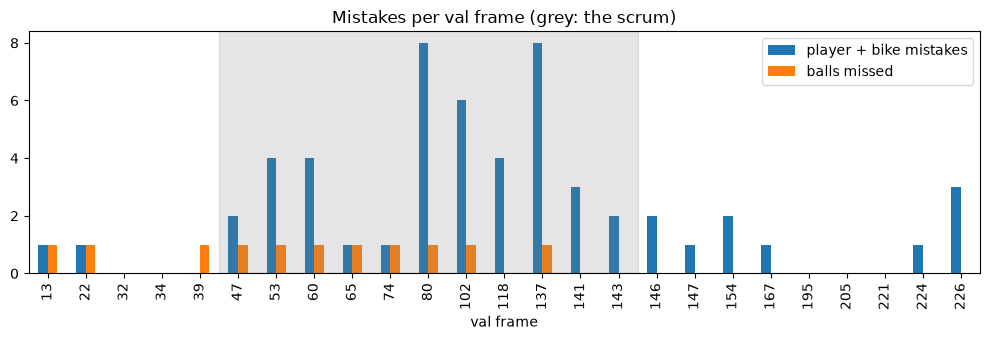

In [9]:
SCRUM = (47, 143)                               # first and last val frame of the scrum, picked by eye from the gallery

per_frame = pd.DataFrame({
    "player + bike mistakes": rider_mistakes.groupby("frame").size(),
    "balls missed": balls[balls.result == "FN"].groupby("frame").size(),
}).reindex(sorted(labels.frame.unique())).fillna(0).astype(int)
in_scrum = per_frame.index.to_series().between(*SCRUM)
print(f"frames {SCRUM[0]}-{SCRUM[1]} ({in_scrum.sum()} of {len(per_frame)} val frames) hold",
      per_frame[in_scrum].sum().to_dict(), "of", per_frame.sum().to_dict())

ax = per_frame.plot.bar(figsize=(10, 3.5), title="Mistakes per val frame (grey: the scrum)")
ax.axvspan(np.flatnonzero(in_scrum)[0] - 0.5, np.flatnonzero(in_scrum)[-1] + 0.5, color="grey", alpha=0.2)
ax.set_xlabel("val frame")
ax.figure.tight_layout()
ax.figure.savefig(REPORTS_DIR / "mistakes_per_frame.png", dpi=120)
plt.show()

**Findings:** frames 47–143, less than half of the val frames, hold 43 of the 55 player and bike mistakes and 8 of the 11 missed balls: about four player and bike mistakes per frame, against under one in the rest.

**Conclusions:** the main weakness, for all three moving classes, is **the scrum**: riders and bikes overlapping with the ball in between. It is also the moment that matters most on a tactical map, so it is worth fixing first. The stretch is picked by eye, so this is a hypothesis, not a proof; the test is the next round: if dataset v2 adds scrum frames, these frames should improve most.

## 6. Confidence per class

Every class uses 0.25 now. What would a separate threshold per class change? We repeat the matching of section 2 at a few thresholds. **Careful:** with 25 val frames, tuning on the same frames would flatter the result, so this shows the direction, not a final value.

In [10]:
rows = []
for threshold in (0.1, 0.25, 0.4, 0.5):
    counts = match(threshold).groupby(["cls", "result"]).size().unstack(fill_value=0)
    for cls in ("ball", "player", "bike"):
        tp, fp, fn = counts.loc[cls, ["TP", "FP", "FN"]]
        rows.append([threshold, cls, tp, fp, fn, round(2 * tp / (2 * tp + fp + fn), 3)])
pd.DataFrame(rows, columns=["threshold", "class", "TP", "FP", "FN", "F1"]).pivot(index="threshold", columns="class")

TP               FP               FN                 F1         \
class     ball bike player ball bike player ball bike player   ball   bike   
threshold                                                                    
0.10        14   83     92   11   57     25   11    6      5  0.560  0.725   
0.25        14   81     90    4   28     12   11    8      7  0.651  0.818   
0.40        14   75     87    4   18      6   11   14     10  0.651  0.824   
0.50        12   72     87    1   10      5   13   17     10  0.632  0.842   

                  
class     player  
threshold         
0.10       0.860  
0.25       0.905  
0.40       0.916  
0.50       0.921

**Findings:**
- **Ball:** a lower threshold adds only extra boxes. The missed balls have no box at any confidence (section 2), so there is nothing to bring back.
- **Bike:** 0.5 instead of 0.25 cuts the extra boxes from 28 to 10 and loses 9 real bikes (81 → 72); F1 goes from 0.818 to 0.842. The poor boxes tend to have lower confidence than the good ones.
- **Player:** a small gain: at 0.4, 6 fewer extra boxes for 3 more misses.

**Conclusions:** a higher `bike` threshold is a cheap improvement for the app (fewer double bikes on the map), but it is a setting, not a fix. The final per-class values should be picked on a held-out test set, not on these 25 frames.

## 7. Failure hypotheses

One row per recurring mistake: the evidence in this notebook, what we think causes it (data, labelling rule or setting), and what to try. These go to the data lead (A) and the modelling lead (B); each result comes back here as a *before → after*.

| # | Mistake | Evidence | Likely cause | What to try | Who |
|---|---|---|---|---|---|
| 1 | **Ball missed in the scrum** | 10 of 11 missed balls get no box at any confidence (§2); found 8 of 8 when touching ≤ 1 rider/bike box, 0 of 4 at ≥ 3 (§3); 8 of 11 misses in frames 47–143 (§5) | Half-hidden, blurred balls are labelled (our occlusion and blur rules), but only 9 of 48 train balls are in a crowd, against 17 of 25 val balls (§3) | Label more frames with the ball inside a scrum (dataset v2), and keep scrum frames in the test set too | A |
| 2 | **Ball boxes not tight** | Ball AP50-95 0.226 against AP50 0.521 (§1); extra ball boxes all next to the real ball (§2) | At `imgsz=640` the 3024 px frame shrinks 4.7×, so the ball is ~8 px and a 2 px shift costs a lot of IoU | Train at `imgsz=1280` (E2 on Colab), where the ball is ~15 px | B |
| 3 | **Possible label mistakes** | Frames 53 and 74: no ball inside the label box (§3, §4) | Box drawn on a rider's head (53) and on a shoe (74) instead of on the ball | Check both against the video, fix or remove the labels, run this notebook again | A |
| 4 | **Split and partial bike boxes** | 28 extra bike boxes, nearly all poor boxes, mostly in frames 47–143 (§2, §4, §5) | Overlapping bikes: the model splits one bike or boxes the visible half; few training frames this crowded | More scrum frames (as #1); check that everyone boxes overlapping bikes the same way (rule: every bike its own box, even when they overlap) | A |
| 5 | **Extra bike boxes on the map** | Bike threshold 0.5 instead of 0.25: 28 → 10 extra boxes, 9 bikes lost (§6) | Poor boxes have lower confidence than good ones | A per-class confidence in the app, higher for `bike`; pick the value on a test set | B, D |
| 6 | **Duplicate rider boxes** | 12 extra player boxes, 6 of them duplicates, all on real riders (§2) | Overlapping riders | Same data fix as #1; try NMS `iou` 0.5 instead of the default 0.7 | B |
| 7 | **Referee in a player box** | Not in val, so the scores cannot show it; in the full video frames 799–806 and 1021–1027 (notebook 04, §4b) | Our rules leave the referee unlabelled; in these frames he stands among or in front of the riders | Add a few such frames to dataset v2 (after frame 234, referee not boxed) and check them on the test set | A |

**What went right:** in the val frames the fine-tuned model boxes no spectators, officials or referee as players (§2), the pretrained model's worst problem. That is the clearest sign that our labels taught it something COCO did not know, even if the referee still slips in now and then (#7).

**Next round:** when dataset v2 and E2 exist, change `MODEL` in Settings, run this notebook again and add the *before → after* to the table.